Initialising of libraries

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
df=pd.read_csv('expense_tracker_400_rows.csv')
df.head()

,date,amount,category,description
0,2026-01-01,402.0,transport,Taxi fare
1,2026-01-01,1275.0,utility,Mobile recharge
2,2026-01-02,2150.0,utility,Mobile recharge
3,2026-01-02,692.0,utility,Mobile recharge
4,2026-01-02,635.0,utility,Internet bill


In [42]:
df.isnull().sum()


,0
date,0
amount,0
category,0
description,0
month,0


In [47]:
df['date']=pd.to_datetime(df['date'])

In [26]:
df['date']=df['date'].fillna(df['date'].mode()[0])


In [25]:
df["amount"]=df['amount'].fillna(df["amount"].mean())

In [29]:
df["category"]=df['category'].fillna(df["category"].mode()[0])

In [30]:
df["description"]=df['description'].fillna(df["description"].mode()[0])

In [38]:
total_spending=df['amount'].sum()
print(total_spending)

323991.38613861386


In [52]:
df['month']=df['date'].dt.month

In [49]:
average_spending=df.groupby('month')['amount'].mean()
print(average_spending)

month
1.0     853.844444
2.0     832.761905
3.0     878.333333
4.0     783.511628
5.0     699.212766
6.0     723.770833
7.0     725.638889
8.0     937.260870
9.0     699.500000
10.0    780.956522
Name: amount, dtype: float64


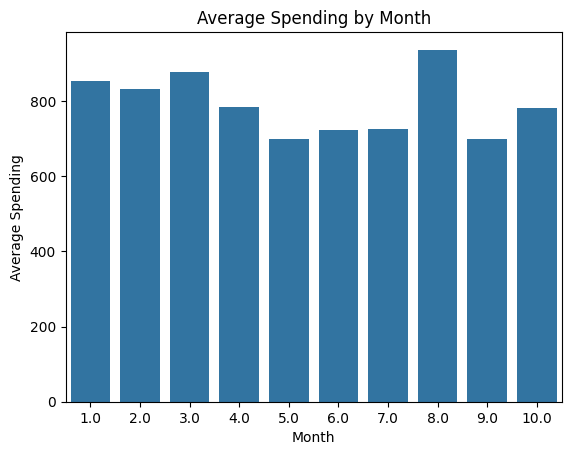

In [60]:
average_spending=df.groupby('month')['amount'].mean()
sns.barplot(x=average_spending.index,y=average_spending.values)
plt.xlabel('Month')
plt.ylabel('Average Spending')
plt.title('Average Spending by Month')
plt.show()

In [54]:
category_spending=df.groupby('category')['amount'].sum()
print(category_spending)

category
entertainment     76736.0
food              47397.0
transport         41702.0
utility          149903.0
Name: amount, dtype: float64


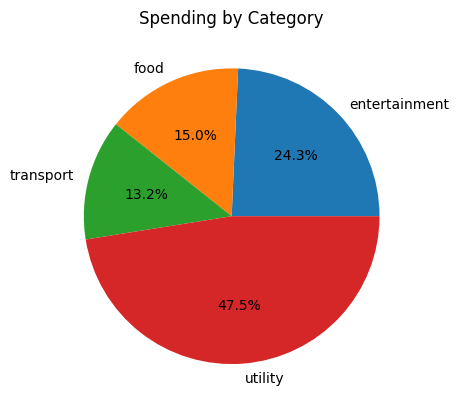

In [59]:
category_spending=df.groupby('category')['amount'].sum()
plt.pie(category_spending,labels=category_spending.index,autopct='%1.1f%%')
plt.title('Spending by Category')
plt.show()

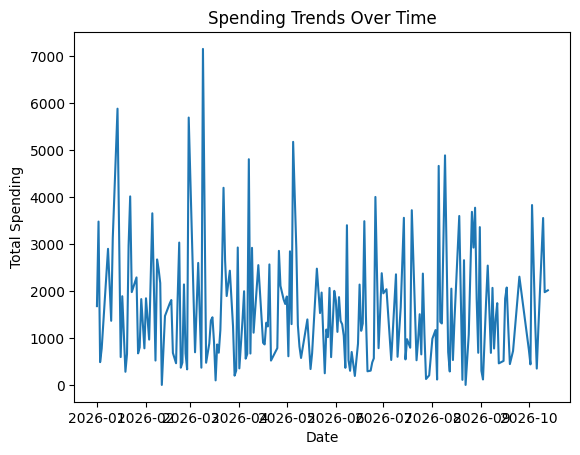

In [61]:
trends_spending=df.groupby('date')['amount'].sum()
plt.plot(trends_spending.index,trends_spending.values)
plt.xlabel('Date')
plt.ylabel('Total Spending')
plt.title('Spending Trends Over Time')
plt.show()

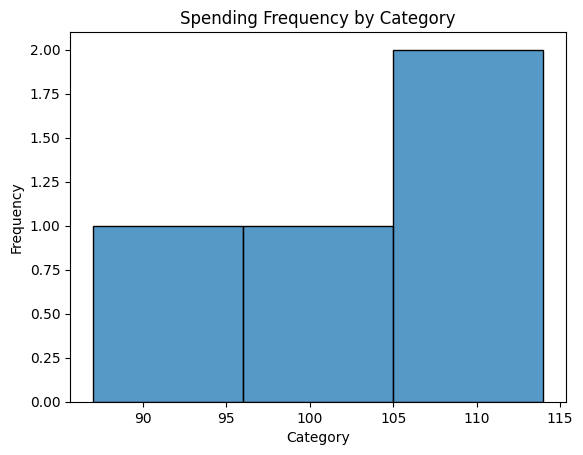

In [72]:
frequency_spending=df['category'].value_counts()
sns.histplot(frequency_spending.values,bins=3)
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.title('Spending Frequency by Category')
plt.show()